# USA Housing Rental Price Analysis

**Business question:** What drives rental prices, and where does a pricing model systematically under- or over-estimate rent? The goal is to support pricing, amenity and location decisions for property owners.

**Data:** [USA Housing Listings (Kaggle)](https://www.kaggle.com/datasets/austinreese/usa-housing-listings): Craigslist rental listings with price, size, beds/baths, property type, pet/smoking/EV/furnished flags, laundry, parking, location and state.

> **Data note:** the full file (`housing.csv`, 384,977 listings, about 560 MB) is too large for GitHub. Download it from Kaggle into `data/` to reproduce these results; without it the notebook falls back to `data/housing_sample.tsv`, a 632-listing extract, so the code still runs. **The outputs shown here are from the full dataset.**

**Pipeline:** cleaning (duplicates, missing values, outliers), then EDA, then regression models (linear, random forest, gradient boosting), then prediction-error analysis by property type and region.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, explained_variance_score

if os.path.exists('data/housing.csv'):
    raw = pd.read_csv('data/housing.csv'); source = 'FULL dataset'
else:
    raw = pd.read_csv('data/housing_sample.tsv', sep='\t'); source = 'SAMPLE extract'
print(f'Loaded {source}: {raw.shape[0]:,} rows x {raw.shape[1]} columns')
print(raw[['price', 'sqfeet', 'beds', 'baths']].describe().round(1).to_string())

Loaded FULL dataset: 384,977 rows x 22 columns
              price     sqfeet      beds     baths
count  3.849770e+05   384977.0  384977.0  384977.0
mean   8.825700e+03     1059.9       1.9       1.5
std    4.462200e+06    19150.8       3.5       0.6
min    0.000000e+00        0.0       0.0       0.0
25%    8.050000e+02      750.0       1.0       1.0
50%    1.036000e+03      949.0       2.0       1.0
75%    1.395000e+03     1150.0       2.0       2.0
max    2.768307e+09  8388607.0    1100.0      75.0


## 0. Starting point: the original course model
The original capstone notebook fit a linear regression of price on `sqfeet`, `beds` and `baths` on the raw data, without removing outliers. Reproducing it shows why cleaning matters: a few listings with absurd prices (up to \$2.8 billion) dominate the error.

In [2]:
orig = raw[['sqfeet', 'beds', 'baths', 'price']].dropna()
Xo_tr, Xo_te, yo_tr, yo_te = train_test_split(orig[['sqfeet', 'beds', 'baths']], orig['price'], test_size=0.2, random_state=42)
p_orig = LinearRegression().fit(Xo_tr, yo_tr).predict(Xo_te)
print(f"Original model on raw data: R2 = {r2_score(yo_te, p_orig):.5f}, RMSE = ${np.sqrt(np.mean((yo_te - p_orig) ** 2)):,.0f}")
print(f"Max listed price: ${raw['price'].max():,.0f} | listings priced at $0: {(raw['price'] == 0).sum():,}")

Original model on raw data: R2 = -0.00001, RMSE = $9,976,767
Max listed price: $2,768,307,249 | listings priced at $0: 1,307


## 1. Data cleaning
- Drop identifier and free-text columns (`id`, `url`, `region_url`, `image_url`, `description`)
- Remove duplicate listings (reposts of the same unit)
- Remove implausible values: price outside \$300–\$10,000, size outside 200–5,000 sq ft, more than 8 beds or baths
- Keep regions with at least 20 listings, so every market has enough data to model (otherwise a handful of out-of-market listings distort coordinate effects)
- Missing `laundry_options` / `parking_options` become their own `unknown` category; missing coordinates are imputed with the median inside the model pipeline

In [3]:
df = raw.drop(columns=['id', 'url', 'region_url', 'image_url', 'description'])
n0 = len(df)
df = df.drop_duplicates()
n_dup = n0 - len(df)
mask = df['price'].between(300, 10000) & df['sqfeet'].between(200, 5000) & (df['beds'] <= 8) & (df['baths'] <= 8)
n_out = (~mask).sum()
df = df[mask].copy()
for c in ['laundry_options', 'parking_options']:
    df[c] = df[c].fillna('unknown')
counts = df['region'].value_counts()
n_rare = (~df['region'].isin(counts[counts >= 20].index)).sum()
df = df[df['region'].isin(counts[counts >= 20].index)].copy()
print(f'Duplicates removed: {n_dup} | outliers removed: {n_out} | rows in regions with <20 listings removed: {n_rare} | rows remaining: {len(df):,}')
print('\nMissing values after cleaning:'); print(df.isna().sum()[df.isna().sum() > 0].to_string())

Duplicates removed: 191384 | outliers removed: 2710 | rows in regions with <20 listings removed: 127 | rows remaining: 190,756

Missing values after cleaning:
lat     1127
long    1127


## 2. Exploratory analysis

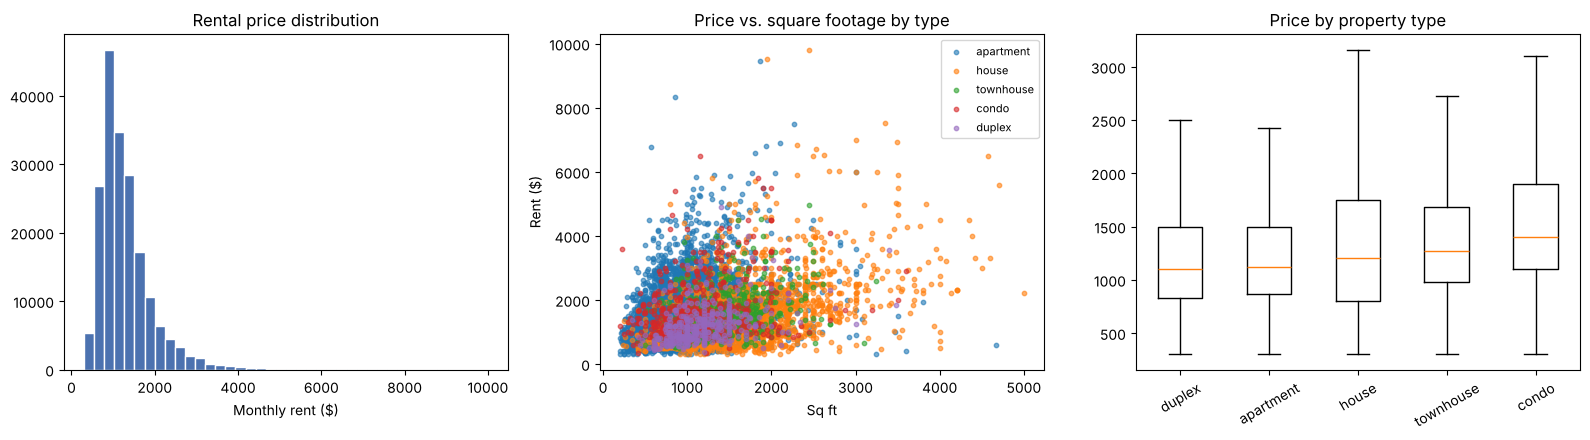

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(df['price'], bins=40, color='#4C72B0', edgecolor='white')
axes[0].set_title('Rental price distribution'); axes[0].set_xlabel('Monthly rent ($)')

top_types = df['type'].value_counts().index[:5]
pts = df.sample(min(len(df), 20000), random_state=0)   # sample points so the scatter stays readable
for t in top_types:
    s = pts[pts['type'] == t]
    axes[1].scatter(s['sqfeet'], s['price'], s=10, alpha=0.6, label=t)
axes[1].set_title('Price vs. square footage by type'); axes[1].set_xlabel('Sq ft'); axes[1].set_ylabel('Rent ($)')
axes[1].legend(fontsize=8)

order = df.groupby('type')['price'].median().loc[top_types].sort_values().index
axes[2].boxplot([df.loc[df['type'] == t, 'price'] for t in order], showfliers=False)
axes[2].set_xticks(range(1, len(order) + 1)); axes[2].set_xticklabels(order)
axes[2].set_title('Price by property type'); axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout()

sqfeet                     0.37
baths                      0.30
beds                       0.20
electric_vehicle_charge    0.12
wheelchair_access          0.09
comes_furnished            0.06
dogs_allowed              -0.02
cats_allowed              -0.04
smoking_allowed           -0.15


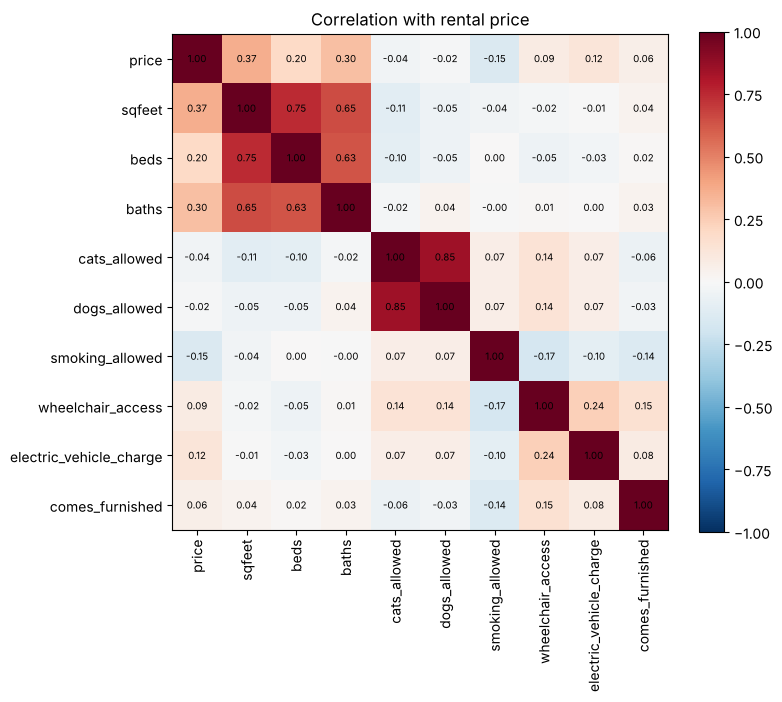

In [5]:
num = ['price', 'sqfeet', 'beds', 'baths', 'cats_allowed', 'dogs_allowed', 'smoking_allowed',
       'wheelchair_access', 'electric_vehicle_charge', 'comes_furnished']
corr = df[num].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=90)
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); ax.set_title('Correlation with rental price')
print(corr['price'].drop('price').sort_values(ascending=False).round(2).to_string())

In [6]:
amen = ['cats_allowed', 'dogs_allowed', 'smoking_allowed', 'wheelchair_access', 'electric_vehicle_charge', 'comes_furnished']
prem = pd.DataFrame({
    'share_of_listings': df[amen].mean(),
    'median_rent_with': [df.loc[df[a] == 1, 'price'].median() for a in amen],
    'median_rent_without': [df.loc[df[a] == 0, 'price'].median() for a in amen]})
prem['difference'] = prem['median_rent_with'] - prem['median_rent_without']
print(prem.round(2).to_string())
lp = df.groupby('laundry_options')['price'].agg(['count', 'median']).sort_values('median')
print('\nMedian rent by laundry option:'); print(lp.to_string())

                         share_of_listings  median_rent_with  median_rent_without  difference
cats_allowed                          0.69            1140.0               1175.0       -35.0
dogs_allowed                          0.66            1149.0               1150.0        -1.0
smoking_allowed                       0.68            1092.0               1277.0      -185.0
wheelchair_access                     0.08            1295.0               1135.0       160.0
electric_vehicle_charge               0.02            1679.0               1140.0       539.0
comes_furnished                       0.06            1200.0               1149.0        51.0

Median rent by laundry option:
                    count  median
laundry_options                  
no laundry on site   2771   850.0
laundry on site     22881   950.0
laundry in bldg     19545   965.0
w/d hookups         35873  1000.0
unknown             35189  1067.0
w/d in unit         74497  1370.0


## 3. Predicting rental price
Features: size, beds, baths, amenity flags, laundry, parking, property type, state and coordinates. Models are compared on a 75/25 split and with cross-validation (5-fold on small data; 3-fold on a 60K-listing subsample for the full dataset).

In [7]:
numeric = ['sqfeet', 'beds', 'baths', 'cats_allowed', 'dogs_allowed', 'smoking_allowed',
           'wheelchair_access', 'electric_vehicle_charge', 'comes_furnished', 'lat', 'long']
categorical = ['type', 'laundry_options', 'parking_options', 'state']
X, y = df[numeric + categorical], df['price']
BIG = len(df) > 50000   # full dataset: lighter forest and CV on a 60K subsample to keep run time reasonable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

pre = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=5), categorical)])
dense = lambda m: make_pipeline(ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=5, sparse_output=False), categorical)]), m)

models = {
    'Baseline (predict mean rent)': make_pipeline(pre, DummyRegressor()),
    'Linear Regression': make_pipeline(pre, LinearRegression()),
    'Random Forest': dense(RandomForestRegressor(n_estimators=100 if BIG else 400, min_samples_leaf=5 if BIG else 2,
                                                 max_samples=0.5 if BIG else None, random_state=0, n_jobs=-1)),
    'Gradient Boosting': dense(HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0)),
}
cv = KFold(3 if BIG else 5, shuffle=True, random_state=0)
X_cv, y_cv = (X.sample(60000, random_state=0), None) if BIG else (X, None)
y_cv = y.loc[X_cv.index]
rows, preds = [], {}
for name, m in models.items():
    m.fit(X_train, y_train); p = m.predict(X_test); preds[name] = p
    rows.append({'Model': name, 'R2': r2_score(y_test, p), 'Explained variance': explained_variance_score(y_test, p),
                 'MAE ($)': mean_absolute_error(y_test, p), 'CV R2': cross_val_score(m, X_cv, y_cv, cv=cv, scoring='r2').mean()})
results = pd.DataFrame(rows).set_index('Model').round(3)
print(results.to_string())

                                 R2  Explained variance  MAE ($)  CV R2
Model                                                                  
Baseline (predict mean rent) -0.000               0.000  467.145 -0.000
Linear Regression             0.484               0.484  303.478  0.494
Random Forest                 0.764               0.764  176.404  0.709
Gradient Boosting             0.742               0.742  206.623  0.733


## 4. Where does the model miss? Error analysis by property type and region
Residual = actual − predicted rent. Positive mean residual means the model **under-estimates** that segment (units rent for more than the model expects); negative means it **over-estimates**.

Best model by test-set MAE: Random Forest

By property type:
                  n  mean_residual  median_abs_pct_error
type                                                    
manufactured    621          -72.4                  10.5
duplex          967          -29.5                  13.1
townhouse      2106          -15.8                   9.2
house          6829           -8.0                  15.0
apartment     35425            0.3                   7.2
condo          1309           11.7                  12.7

Most over-estimated states (model predicts too high):
         n  mean_residual  median_rent
state                                 
mo     284          -81.5        700.0
in     766          -51.2        829.0
ar     393          -49.6        825.0
al     716          -46.2        865.0
sd     253          -44.7        795.0
ms     391          -44.4        809.0
ky     567          -33.3        810.0
id     689          -31.3       1100.0

Most under-estimated states (model pr

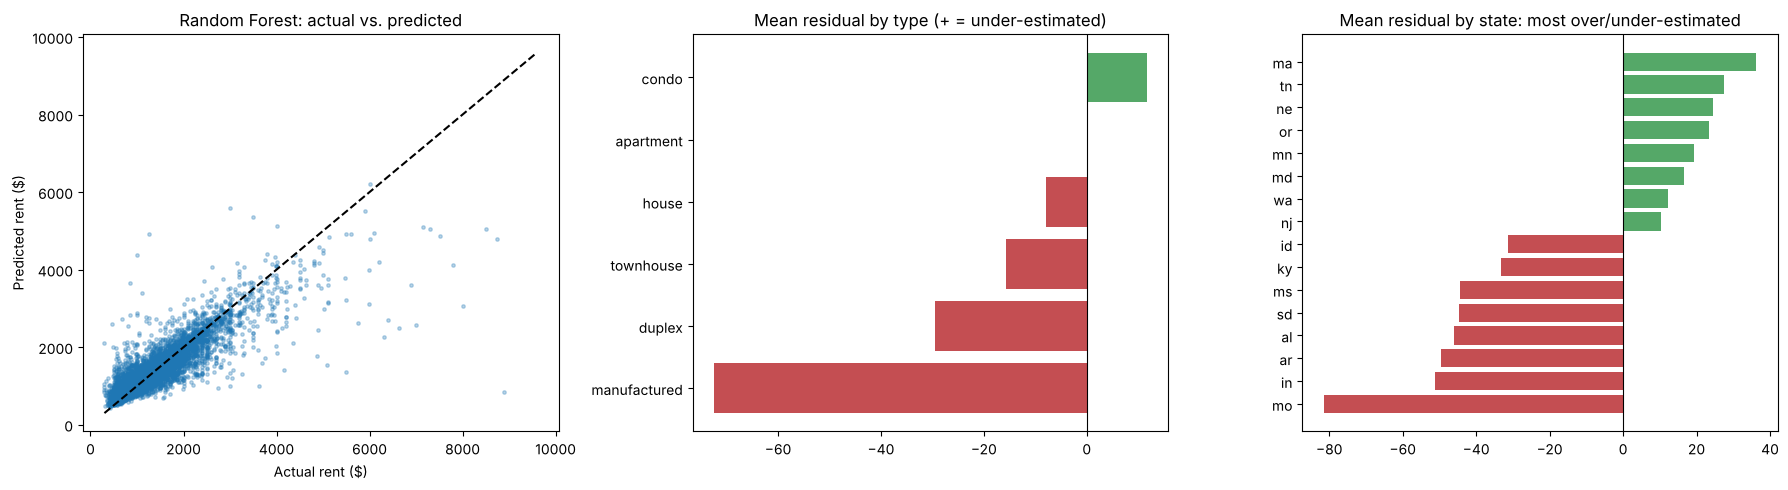

In [8]:
best = results['MAE ($)'].idxmin()
print('Best model by test-set MAE:', best)
err = X_test.assign(actual=y_test, predicted=preds[best], region=df.loc[X_test.index, 'region'])
err['residual'] = err['actual'] - err['predicted']
err['abs_pct_error'] = (err['residual'].abs() / err['actual'] * 100)

min_n = 200 if BIG else 3
by_type = err.groupby('type').agg(n=('residual', 'size'), mean_residual=('residual', 'mean'),
                                  median_abs_pct_error=('abs_pct_error', 'median')).query('n >= @min_n').sort_values('mean_residual')
print('\nBy property type:'); print(by_type.round(1).to_string())

by_state = err.groupby('state').agg(n=('residual', 'size'), mean_residual=('residual', 'mean'),
                                    median_rent=('actual', 'median')).query('n >= @min_n').sort_values('mean_residual')
print('\nMost over-estimated states (model predicts too high):'); print(by_state.head(8).round(1).to_string())
print('\nMost under-estimated states (model predicts too low):'); print(by_state.tail(8).round(1).to_string())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
e_pts = err.sample(min(len(err), 10000), random_state=0)
axes[0].scatter(e_pts['actual'], e_pts['predicted'], s=6, alpha=0.3)
lim = [err[['actual', 'predicted']].min().min(), err[['actual', 'predicted']].max().max()]
axes[0].plot(lim, lim, 'k--'); axes[0].set_xlabel('Actual rent ($)'); axes[0].set_ylabel('Predicted rent ($)')
axes[0].set_title(f'{best}: actual vs. predicted')
axes[1].barh(by_type.index, by_type['mean_residual'], color=np.where(by_type['mean_residual'] > 0, '#55A868', '#C44E52'))
axes[1].axvline(0, color='k', lw=0.8); axes[1].set_title('Mean residual by type (+ = under-estimated)')
ext = pd.concat([by_state.head(8), by_state.tail(8)]) if len(by_state) > 16 else by_state
axes[2].barh(ext.index, ext['mean_residual'], color=np.where(ext['mean_residual'] > 0, '#55A868', '#C44E52'))
axes[2].axvline(0, color='k', lw=0.8); axes[2].set_title('Mean residual by state: most over/under-estimated')
plt.tight_layout()

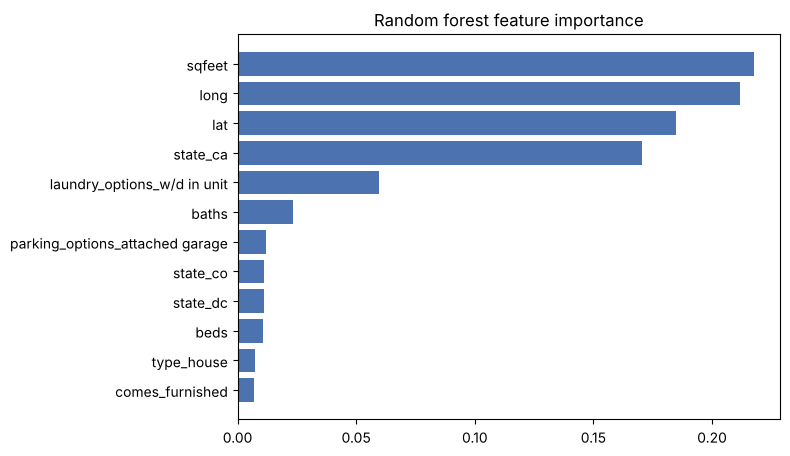

In [9]:
rf = models['Random Forest']
names = rf[0].get_feature_names_out()
imp = pd.Series(rf[-1].feature_importances_, index=names).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh([n.split('__')[-1] for n in imp.index], imp.values, color='#4C72B0')
ax.set_title('Random forest feature importance')

## Summary (full dataset: 384,977 listings, 190,756 after cleaning, 51 states)

**Cleaning mattered most.** Half the listings (191,384) were duplicate reposts, and 2,710 had impossible values (prices of \$0 up to \$2.8 billion). On the raw data, the original course model scored R² = 0.00 with an RMSE of about \$10 million. After cleaning, the same kind of model is meaningful.

| Model | Test R² | MAE | CV R² (3-fold, 60K subsample) |
|---|---|---|---|
| Original course model (raw data) | 0.00 | n/a (RMSE about \$10M) | n/a |
| Baseline (mean rent) | 0.00 | \$467 | 0.00 |
| Linear Regression | 0.48 | \$303 | 0.49 |
| **Random Forest** | **0.76** | **\$176** | 0.71 |
| Gradient Boosting | 0.74 | \$207 | 0.73 |

**Findings**
- **Random forest explains 76% of rent variation** and cuts the typical error from \$467 to \$176 a month (62% lower than the baseline).
- **Location matters as much as size:** square footage, longitude, latitude and being in California are the top four features.
- **In-unit washer/dryer is the most valuable common amenity:** median rent about \$1,370 vs. about \$950 with shared on-site laundry. EV charging carries a premium of about \$540, but only 2% of listings have it.
- **Pet-friendly policies show no rent premium** (median difference under \$40), which matches the original team's t-test (p = 0.32). Smoking-allowed listings rent for about \$185 less.
- **Error analysis by state:** the model over-estimates rent in low-cost states (Missouri by about \$82 a month; Indiana, Arkansas and Alabama by about \$45–50) and under-estimates it in high-cost states (Massachusetts +\$36; Oregon, Maryland, Washington and New Jersey). It pulls prices toward the national average.
- **By property type:** manufactured homes are over-estimated by about \$72 and duplexes by about \$30; apartments, the bulk of the data, are nearly unbiased.